# Interpolate 1D model
This section explains how to query a 1D velocity model, interpolate values, and visualize the results.<br>
Written by Andrea C. Riaño.<br> 
andrea.riano@bsc.es

---
### How to use this notebook

1. Make sure to have python 3.6 or later installed in your PC.
2. Install the required dependencies executing the first cell of this notebook.

In [1]:
import os
import sys
import shutil
sys.path.append("VelocityModel_utils/") 
import subprocess
import numpy as np
import VelocityModel_utils

# List of required libraries
required_libraries = [
    "cartopy", "folium", "joblib", "matplotlib", "netCDF4", 
    "numpy", "pandas", "psutil", "pyproj", "scipy", 
    "shapely", "simplekml", "tqdm"
]

# Check if libraries are installed
missing_libraries = []
for lib in required_libraries:
    try:
        __import__(lib)
    except ImportError:
        missing_libraries.append(lib)

# Install missing libraries
if missing_libraries:
    print(f"The following dependencies are missing: {', '.join(missing_libraries)}")
    print("Installing missing dependencies quietly...")
    try:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-r", "requirements.txt", "-q"],
            stdout=subprocess.DEVNULL,  # Suppresses standard output
            stderr=subprocess.DEVNULL   # Suppresses standard error
        )
        print("Missing dependencies installed successfully.")
    except subprocess.CalledProcessError as e:
        print(f"An error occurred during installation: {e}")
else:
    print("All required dependencies are already installed.")

import pandas as pd

All required dependencies are already installed.


---

## Overview  

This notebook provides four examples demonstrating how to use the `VelocityModel_utilities` functions to query and interpolate 1D velocity models. Additionally, it shows how to assign interpolated values in depth to a 3D mesh defined by the user for CyberShake simulations.  

### Examples  

- **Example 1**: Interpolates a **1D linear velocity model**, mapping values to coordinate points.  
- **Example 2**: Interpolates a **1D discontinuous (stepwise) velocity model**, mapping values to coordinate points.  
- **Example 3**: Uses a **realistic 1D velocity model for Southern California** and assigns properties to a user-defined domain based on the provided C1 coordinate, model rotation, and domain dimensions in local x and y coordinates.  
- **Example 4**: Extends Example 3 by incorporating a **1D model with Qp and Qs values**, increasing the number of properties per coordinate from 3 to 5.  

---

## Important Note  

It is recommended to use this notebook **only for the examples presented here**.  

To define your own case, first follow the examples in this jupyter notebook. Then, explore the script **`run_1Dinterpolator.sh`** to learn how to run a **1D interpolation and mapping to a 3D mesh** (as demonstrated in Example 3) in a more automated way.  

---
## Concepts and input parameters description
### Cybershake domain's corners conventions

     (North ↑)
         ^ 
         |
        C2 ------------------- C3
         |                     |  
         |       Model         |  
         |       Domain        |  
         |                     |  
        C1 ------------------- C4 --> (East →)

### Domain rotation
<img src="VelocityModel_utils/modelrot.png" width="350">

### Path to the Input Data Folder and Velocity Model File
- **`input_folder`** = `Example_3DVelocityModel/inputData/`  
  Path to the folder containing the input data.  
- **`vm_file`** = `cvms5_1d_depth_socal.nc`  
  The velocity model (VM) file containing 3D velocity model data used for interpolation.  
  Possible input formats: `csv`, `txt`, `nc`, `json`.  
- **`velocity_units`** = `km/s`  
  Units for velocity values in the input velocity model (vm_file). 
- **`density_units`** = `kg/m³`  
  Units for density values in the input velocity model (vm_file).  

### Anelastic or Elastic Model  
- **`is_anelastic`** = `False`  
  Set to `False` for an elastic model (Vp, Vs, and Rho only).  
  Set to `True` for an anelastic model.  

### Geographic Coordinates of the Model Domain  
- **`model_lon`** = `-119.38`  
  Longitude of the domain's C1 corner (degrees).  
- **`model_lat`** = `34.13`  
  Latitude of the domain's C1 corner (degrees).  

### Model Domain Dimensions (in Kilometers)  
- **`x_length`** = `200`  
  Length along the local X-axis, which is the distance from C1 to C4 and is equal to the distance from C2 to C3. 
- **`y_length`** = `120`  
  Length along the local Y-axis, which is the distance from C1 to C2 and is equal to the distance from C4 to C3.  
- **`z_length`** = `30`  
  Depth of the model. 

### Model Rotation  
- **`model_rot`** = `-90`  
  Rotation of the simulation domain.  
  A value of `-90` means the model is rotated 90° counterclockwise around C1, meaning C2 moves above C1.  

### Grid Configuration  
- **`grid_spacing`** = `2`  
  Distance between each grid point in the model (in km).  

### Model Region  
- **`region`** = `SouthernCalifornia`  
  This refers to the name of the region, which is used when naming the output files.  

### Variables and Plot Configuration  
- **`variable_name`** = `Vp`  
  Variable to plot. Options: `'Vp'`, `'Vs'`, `'Rho'`. If `is_anelastic=True`, also `'Qp'` and `'Qs'`.  
- **`plane_type`** = `XZ`  
  Plane to plot (`XZ` or `YZ` at index in the local Y or X direction, respectively).  
- **`index`** = `10`  
  Index location for the plane to plot.   
- **`index_z`** = `0`  
  XY surface is plotted by default at the depth corresponding to this index.  

### Dynamic Map Configuration  
- **`Domain_dynmap`** = `True`  
  When Domain_dynmap is set to True, the dynamic map of the domain will be shown in this notebook. 
- **`Grid_dynmap`** = `False`  
  When Grid_dynmap is set to True, the dynamic mapping of the model grid (can take time for large grids).  

### Output Folder  
- **`output_folder`**  
  Folder path where output files will be saved. 

---
# Example 1: 1D linear model
## Step 1: Load the 1D Velocity Model
The input model should be in a tab-delimited format. Lets inspect how this file looks, and make a plot of the input model.

In [2]:
file_path = "Example_1DVelocityModel_Elastic/inputData/1d_model.txt"
output_folder_AWP="Example_1DVelocityModel_Elastic/outputData/AWP_inputfiles/"
output_folder_Figures="Example_1DVelocityModel_Elastic/outputData/Figures/"
df = pd.read_csv(file_path, delimiter='\t')
print(df.head())

# Remove existing output directories to prevent errors during execution.
# The binary file generation reads only the first modelcoords file it encounters.
if os.path.isdir(output_folder_AWP):
    print(f"Removing pre-existing output directory to avoid runtime conflicts:{output_folder_AWP}")
    shutil.rmtree(output_folder_AWP)

  Depth(km) Vp(km/s)  Vs(km/s)  Density(g/cm³)
0                  0    6.00     3.50     2.70
1                  10   6.50     3.70     2.75
2                  20   7.00     3.90     2.80
3                  30   7.50     4.20     2.85
Removing pre-existing output directory to avoid runtime conflicts:Example_1DVelocityModel_Elastic/outputData/AWP_inputfiles/


## Step 2: Define the Coordinates of Interest

These coordinates represent points within your 3D model mesh for Cybershake. In the example below, we will inspect three sets of `(x, y, z)` coordinates. 

As observed above, the velocity model is **elastic** (i.e., Qp and Qs are not provided). Therefore, we set the `is_anelastic` flag to `False`, indicating that the interpolation function will compute only three wave properties: **Vp**, **Vs**, and **Rho**.

```python
coordinates = [(0, 0, 5), (0, 0, 10), (0, 0, 15)]
is_anelastic = False
```

We will provide three inputs:
- File path to the 1D velocity model.
- Flag indicating whether the model is elastic (`is_anelastic = False`).
- Coordinates to query: `[(0, 0, 5), (0, 0, 10), (0, 0, 15)]`.

### Expected Outputs

- Interpolated values of the wave parameters (**Vp**, **Vs**, and **Rho**) at the queried coordinates.
- A visualization of the 1D input model and scatter points representing the interpolated values.


In [3]:
# Coordinates to query: In the 3D representation, points at the same depth will be assigned the same properties
coordinates = [(0, 0, 5), (0, 0, 10), (0, 0, 15)]  
is_anelastic = False

## Step 3: Interpolate Data
First, we will read the 1D input model data with the function **parse_1d_model** and then we will interpolate data using the function **interpolate_1d_model**. Both functions are located in the file **VelocityModel_utils.py** which we loaded at the begining of the notebook with the following command. 

```python
import VelocityModel_utils
```

In [4]:
# Read the 1D model 
model_data = VelocityModel_utils.parse_1d_model(file_path, is_anelastic=is_anelastic)

# Convert units of velocities and density from km/s and g/cm3 to m/s and kg/m3
model_data= VelocityModel_utils.convert_units(model_data,'km/s','g/cm3')

# Interpolate using a 'linear method'
interpolated_values = VelocityModel_utils.interpolate_1d_model(model_data, coordinates, method='linear', is_anelastic=is_anelastic)

[interpolate_1d_model] n_jobs = 7
[interpolate_1d_model] batch_size = 10000
[interpolate_1d_model] num_points = 3
[interpolate_1d_model] num_batches = 1


Interpolating: 100%|██████████| 1/1 [00:00<00:00, 625.18batch/s]


--- Quality Checks of the Interpolation ---
| Parameter  | NaN?  | Inf?  | Min    | Max    |
|-----------|------|------|--------|--------|
| vp         | 0    | 0    | 6240.00 | 6740.74 |
| vs         | 0    | 0    | 3597.22 | 3797.37 |
| rho        | 0    | 0    | 2725.00 | 2775.00 |
| Vp/Vs Ratio | -    | -    |   1.73 |   1.78 |
---------------------------------------------------



## Step 4: Visualize Results
To visualize the results, we need to create a dictionary (**`scatter_data`**). This dictionary will define:

- The depths of the queried points.
- The interpolated values for **Vp**, **Vs**, and **Rho** (and optionally **Qp** and **Qs** if the model is anelastic).

The function requires the scatter points to be organized in this format to plot them correctly alongside the 1D input model.

Plot of the velocity model and the interpolated data as scatter points


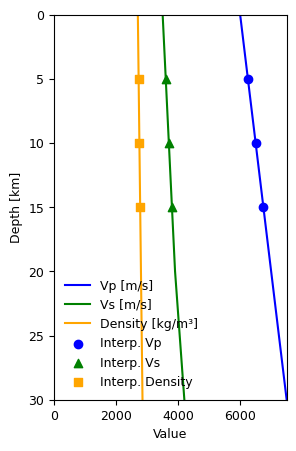

Plots saved in Example_1DVelocityModel_Elastic/outputData/Figures/


In [5]:
scatter_data = {
    'Depth': [coord[2] for coord in coordinates],  # Extracting Z (depth) coordinates
    'Vp': interpolated_values['vp'].tolist(),      # Vp values
    'Vs': interpolated_values['vs'].tolist(),      # Vs values
    'Rho': interpolated_values['rho'].tolist(),    # Rho values
}

# Assuming 'model_data' was parsed using parse_1d_model, plot the 1D model and interpolated values. 
print('Plot of the velocity model and the interpolated data as scatter points')
VelocityModel_utils.plot_1d_model(output_folder_Figures,model_data, is_anelastic=is_anelastic, transition_type="linear",scatter_data=scatter_data, display=True)

---
# Example 2: Elastic model with discontinuities

In [6]:
file_path_discontinous = "Example_1DVelocityModel_Elastic/inputData/1d_model_discontinous.txt" 
df = pd.read_csv(file_path_discontinous, delimiter='\t')
print(df.head())

  Depth(km)  Vp(km/s)  Vs(km/s)  Density(g/cm³)
0                    0    6.0     3.5     2.700
1                    10   6.5     3.7     2.750
2                    10   7.0     4.0     2.760
3                    20   7.5     4.2     2.800
4                    30   8.0     4.5     2.850


[interpolate_1d_model] n_jobs = 7
[interpolate_1d_model] batch_size = 10000
[interpolate_1d_model] num_points = 3
[interpolate_1d_model] num_batches = 1


Interpolating: 100%|██████████| 1/1 [00:00<00:00, 2193.67batch/s]


--- Quality Checks of the Interpolation ---
| Parameter  | NaN?  | Inf?  | Min    | Max    |
|-----------|------|------|--------|--------|
| vp         | 0    | 0    | 6500.00 | 7500.00 |
| vs         | 0    | 0    | 3700.00 | 4200.00 |
| rho        | 0    | 0    | 2750.00 | 2800.00 |
| Vp/Vs Ratio | -    | -    |   1.76 |   1.79 |
---------------------------------------------------



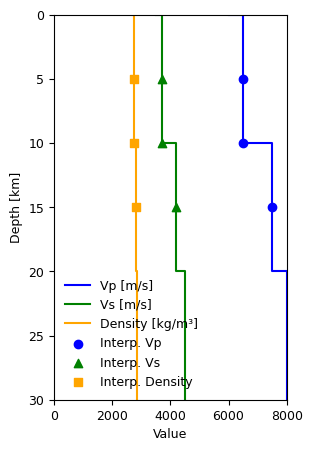

Plots saved in Example_1DVelocityModel_Elastic/outputData/Figures/


In [7]:
# 1D model with discontinuities - the 1D model has to be provided in tab-delimited format
model_data_d = VelocityModel_utils.parse_1d_model(file_path_discontinous, is_anelastic=is_anelastic)

# Convert units of velocities and density from km/s and g/cm3 to m/s and kg/m3
model_data_d= VelocityModel_utils.convert_units(model_data_d,'km/s','g/cm3')

# Stepwise behavior using 'next' in the definition of 'method'
interpolated_values = VelocityModel_utils.interpolate_1d_model(model_data_d, coordinates, method='next', is_anelastic=is_anelastic)

scatter_data = {
    'Depth': [coord[2] for coord in coordinates],  # Extracting Z (depth) coordinates
    'Vp': interpolated_values['vp'].tolist(),      # Vp values
    'Vs': interpolated_values['vs'].tolist(),      # Vs values
    'Rho': interpolated_values['rho'].tolist(),    # Rho values
}

VelocityModel_utils.plot_1d_model(output_folder_Figures,model_data_d, is_anelastic=is_anelastic, transition_type="stepwise",scatter_data=scatter_data, display=True)

---
# Example 3: Generate velocity model for a 3D Mesh using as input a 1D elastic model.

## Step 1: Load the 1D Velocity Model:
For an Elastic simulation, a 1D velocity model typically consists of layers, each with a specific depth range, velocities (Vp and Vs), and density. We will use the velocity model from the first example. Keep in mind that if you use the function **parse_1d_model**  in **VelocityModel_utils**, the velocity model should be in a tab-delimited format.

In [8]:
file_path = "Example_1DVelocityModel_Elastic/inputData/SoCal_1Dmodel.csv"
is_anelastic = False
model_data = VelocityModel_utils.parse_1d_model(file_path, is_anelastic=is_anelastic)

# Convert units of density from g/cm3 to kg/m3. 
model_data = VelocityModel_utils.convert_units(model_data,'km/s','g/cm3')

## Step 2: Prepare the 3D Mesh files required by Cybershake:
The 3D mesh represents the spatial domain of the area of interest and consists of nodes with a spacing that is defined so tht the simulation can solve the wave propagation for a selected resolution (minimum Vs and Maximum frequency).  

In [9]:
# Generate velocity model files for Southern California
model_lon=-119.38
model_lat=34.13
x_length=200    #km 
y_length=120    #km 
z_length=30     #km 
model_rot=-60   #deg
grid_spacing=2  #km 
Region= "SouthernCalifornia"

# Name of output files
domain_data = f'{int(x_length)}km_{int(y_length)}km_{int(z_length)}km_Spacing_{int(float(grid_spacing)*1000)}m'

# Generate velocity model coordinates file
VelocityModel_utils.create_model_coords_file(
    file_name=domain_data,
    site_name=Region,
    model_lon=model_lon,
    model_lat=model_lat,
    x_length=x_length,
    y_length=y_length,
    model_rot=model_rot,
    grid_spacing=grid_spacing,
    output_folder=output_folder_AWP)

# Generate model box
VelocityModel_utils.generate_modelbox_file(
    file_name=domain_data,
    site_name=Region,
    model_lon=model_lon,
    model_lat=model_lat,
    x_length=x_length,
    y_length=y_length,
    model_rot=model_rot,
    output_folder=output_folder_AWP)

# Generate gridout file
VelocityModel_utils.create_gridout_file(
    file_name=domain_data, 
    site_name=Region,
    x_length=x_length,
    y_length=y_length,
    z_length=z_length,
    grid_spacing=grid_spacing,
    output_folder=output_folder_AWP)

#  Plot domain on surface - dynamic map
VelocityModel_utils.plot_modelbox_with_folium(
    region=Region,
    model_lon=model_lon,
    model_lat=model_lat,
    x_length=x_length,
    y_length=y_length,
    model_rot=model_rot,
    output_folder=output_folder_Figures,
    display=True)

File 'Example_1DVelocityModel_Elastic/outputData/AWP_inputfiles/200km_120km_30km_Spacing_2000m.model_coords_SouthernCalifornia' created successfully.
File 'Example_1DVelocityModel_Elastic/outputData/AWP_inputfiles/200km_120km_30km_Spacing_2000m.modelbox_SouthernCalifornia' has been created.
File 'Example_1DVelocityModel_Elastic/outputData/AWP_inputfiles/200km_120km_30km_Spacing_2000m.gridout_SouthernCalifornia' created successfully.
KML file saved to Example_1DVelocityModel_Elastic/outputData/Figures/SouthernCalifornia_domain.kml
HTML map saved to Example_1DVelocityModel_Elastic/outputData/Figures/SouthernCalifornia_domain.html


In [10]:
# Plot mesh points on surface 
model_coords_file = output_folder_AWP + domain_data + '.model_coords_' + Region
VelocityModel_utils.plot_and_export_grid_map(
    region=Region, 
    model_coords_file=model_coords_file,
    output_folder=output_folder_Figures)

HTML map saved to Example_1DVelocityModel_Elastic/outputData/Figures/SouthernCalifornia_grid.html
KML file saved to Example_1DVelocityModel_Elastic/outputData/Figures/SouthernCalifornia_grid.kml


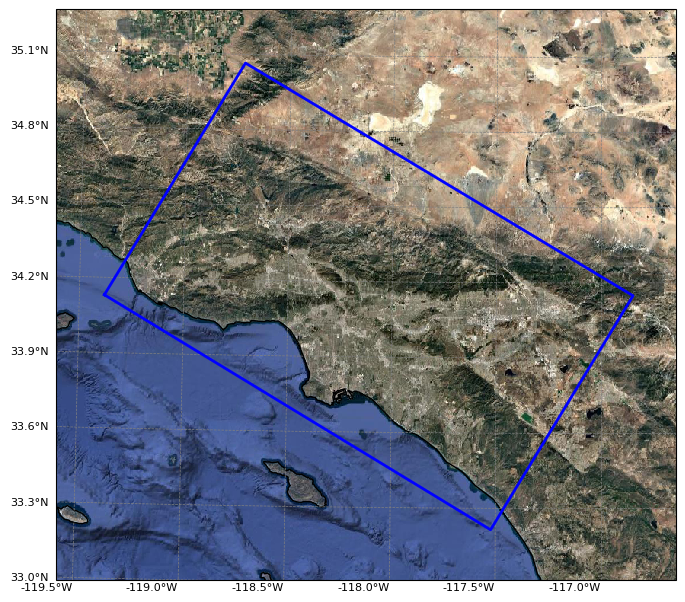

In [11]:
#  Plot domain on surface - static map 
VelocityModel_utils.plot_modelbox_with_cartopy(
    region=Region,
    model_lon=model_lon,
    model_lat=model_lat,
    x_length=x_length,
    y_length=y_length,
    model_rot=model_rot,
    output_folder=output_folder_Figures,
    display=True)

## Step 3: Map the 1D Model to the 3D Mesh:
Iterate over the nodes of the 3D mesh. Assign a velocity to each node based on its depth (z-coordinate) by interpolating or looking up values from the 1D model. 

In [12]:
# Calculate the grid point in each direction based on the spacing
spacing = grid_spacing
X = np.arange(0, x_length, spacing, dtype=np.float32)
Y = np.arange(0, y_length, spacing, dtype=np.float32)
Z = np.arange(0, z_length, spacing, dtype=np.float32)

# Create the grid
Z_grid, Y_grid, X_grid = np.meshgrid(Z, Y, X, indexing='ij')

# Stack coordinates
coordinates = np.column_stack([X_grid.ravel(), Y_grid.ravel(), Z_grid.ravel()])
  
# Delete unneeded variables
del Z_grid, Y_grid, X_grid
VelocityModel_utils.force_gc()

# Print the result
print("Grid as column vector (X, Y, Z) with desired order:")
print("Coordinates:",coordinates)

Grid as column vector (X, Y, Z) with desired order:
Coordinates: [[  0.   0.   0.]
 [  2.   0.   0.]
 [  4.   0.   0.]
 ...
 [194. 118.  28.]
 [196. 118.  28.]
 [198. 118.  28.]]


[interpolate_1d_model] n_jobs = 7
[interpolate_1d_model] batch_size = 10000
[interpolate_1d_model] num_points = 90000
[interpolate_1d_model] num_batches = 9


Interpolating: 100%|██████████| 9/9 [00:00<00:00, 2030.92batch/s]



--- Quality Checks of the Interpolation ---
| Parameter  | NaN?  | Inf?  | Min    | Max    |
|-----------|------|------|--------|--------|
| vp         | 0    | 0    | 5158.03 | 6963.18 |
| vs         | 0    | 0    | 2982.83 | 4252.17 |
| rho        | 0    | 0    | 2736.36 | 3016.79 |
| Vp/Vs Ratio | -    | -    |   1.64 |   1.73 |
---------------------------------------------------

Plot of the velocity model and the interpolated data as scatter points


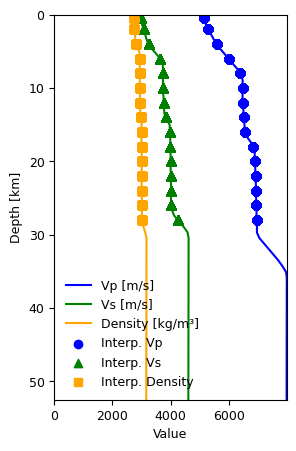

Plots saved in Example_1DVelocityModel_Elastic/outputData/Figures/


In [13]:
# Interpolate the 1D model
interpolated_values = VelocityModel_utils.interpolate_1d_model(model_data, coordinates, grid_spacing = spacing, method='linear', is_anelastic=is_anelastic)

scatter_data = {
    'Depth': [coord[2] for coord in coordinates],  # Extracting Z (depth) coordinates
    'Vp': interpolated_values['vp'].tolist(),      # Vp values
    'Vs': interpolated_values['vs'].tolist(),      # Vs values
    'Rho':interpolated_values['rho'].tolist(),     # Rho values
}

# Assuming 'model_data' was parsed using parse_1d_model, plot the 1D model and interpolated values. 
print('Plot of the velocity model and the interpolated data as scatter points')
VelocityModel_utils.plot_1d_model(output_folder_Figures, model_data, is_anelastic=is_anelastic, transition_type="linear",scatter_data=scatter_data,display=True)

## Step 4: Save binary model and plot the results:

In [14]:
# Create binary file
VM_binFile=VelocityModel_utils.save_binary_model(region="SoCal_Elastic", 
                  NX=len(X), NY=len(Y), NZ=len(Z), Dhkm=grid_spacing, 
                  z=coordinates[:, 2], Vp=interpolated_values['vp'], Vs=interpolated_values['vs'], Rho=interpolated_values['rho'], Qp=None, Qs=None, elastic=True,output_folder=output_folder_AWP)

Using model_coords: Example_1DVelocityModel_Elastic/outputData/AWP_inputfiles/200km_120km_30km_Spacing_2000m.model_coords_SouthernCalifornia
Binary file created: Example_1DVelocityModel_Elastic/outputData/AWP_inputfiles/SoCal_Elastic_100x60x15_Dh2000m.bin


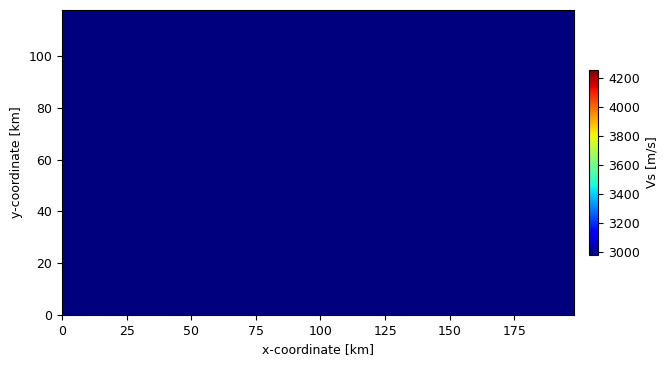

Figure saved in: Example_1DVelocityModel_Elastic/outputData/Figures/Vs_XY_DepthIndex_0.svg


In [15]:
# Plot XY surface 
VelocityModel_utils.plot_surface_XY(
    binary_file_path=VM_binFile,
    variable_name='Vs',
    index=0,
    num_x=len(X),
    num_y=len(Y),
    num_z=len(Z), 
    variable_names=['Vp', 'Vs', 'Rho'],
    output_folder=output_folder_Figures,
    x_coords = coordinates[:, 0],
    y_coords = coordinates[:, 1],
    z_coords = coordinates[:, 2],
    display=True)

Figure saved in: Example_1DVelocityModel_Elastic/outputData/Figures/Vs_XZ_ycoordIndex_10.svg


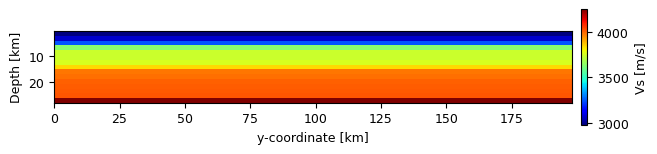

In [16]:
# Plot XZ or YZ surface 
VelocityModel_utils.plot_surface_XZorYZ(
    binary_file_path=VM_binFile,
    variable_name='Vs',
    index=10, 
    num_x=len(X), 
    num_y=len(Y), 
    num_z=len(Z), 
    variable_names=['Vp', 'Vs', 'Rho'], 
    plane_type='XZ',
    output_folder=output_folder_Figures,
    x_coords = coordinates[:, 0],
    y_coords = coordinates[:, 1],
    z_coords = coordinates[:, 2])

---
# Example 4: 1D Velocity Model with Qp and Qs

Removing pre-existing output directory to avoid runtime conflicts:Example_1DVelocityModel_QpQs/outputData_QpQs/AWP_inputfiles/
File 'Example_1DVelocityModel_QpQs/outputData_QpQs/AWP_inputfiles/200km_120km_30km_Spacing_2000m.model_coords_SouthernCalifornia' created successfully.
File 'Example_1DVelocityModel_QpQs/outputData_QpQs/AWP_inputfiles/200km_120km_30km_Spacing_2000m.modelbox_SouthernCalifornia' has been created.
File 'Example_1DVelocityModel_QpQs/outputData_QpQs/AWP_inputfiles/200km_120km_30km_Spacing_2000m.gridout_SouthernCalifornia' created successfully.
KML file saved to Example_1DVelocityModel_QpQs/outputData_QpQs/Figures/SouthernCalifornia_domain.kml
HTML map saved to Example_1DVelocityModel_QpQs/outputData_QpQs/Figures/SouthernCalifornia_domain.html
Grid as column vector (X, Y, Z) with desired order:
Coordinates: [[  0.   0.   0.]
 [  2.   0.   0.]
 [  4.   0.   0.]
 ...
 [194. 118.  28.]
 [196. 118.  28.]
 [198. 118.  28.]]
[interpolate_1d_model] n_jobs = 7
[interpolate_1

Interpolating: 100%|██████████| 9/9 [00:00<00:00, 3268.57batch/s]



--- Quality Checks of the Interpolation ---
| Parameter  | NaN?  | Inf?  | Min    | Max    |
|-----------|------|------|--------|--------|
| vp         | 0    | 0    | 5158.03 | 6963.18 |
| vs         | 0    | 0    | 2982.83 | 4252.17 |
| rho        | 0    | 0    | 2736.36 | 3016.79 |
| qp         | 0    | 0    |  89.49 | 127.60 |
| qs         | 0    | 0    |  59.66 |  85.07 |
| Vp/Vs Ratio | -    | -    |   1.64 |   1.73 |
---------------------------------------------------



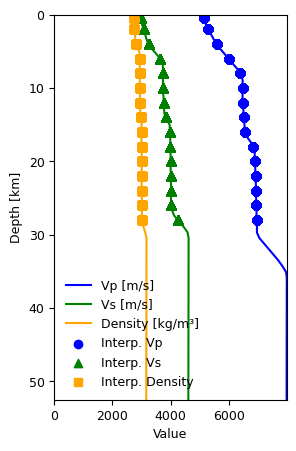

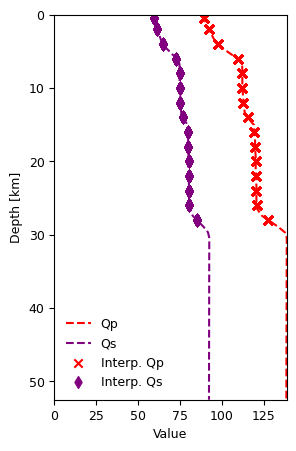

Plots saved in Example_1DVelocityModel_QpQs/outputData_QpQs/Figures/
Using model_coords: Example_1DVelocityModel_QpQs/outputData_QpQs/AWP_inputfiles/200km_120km_30km_Spacing_2000m.model_coords_SouthernCalifornia
Binary file created: Example_1DVelocityModel_QpQs/outputData_QpQs/AWP_inputfiles/SoCal_Anelastic_100x60x15_Dh2000m.bin
Figure saved in: Example_1DVelocityModel_QpQs/outputData_QpQs/Figures/Qp_XY_DepthIndex_0.svg
Figure saved in: Example_1DVelocityModel_QpQs/outputData_QpQs/Figures/Qp_XZ_ycoordIndex_10.svg


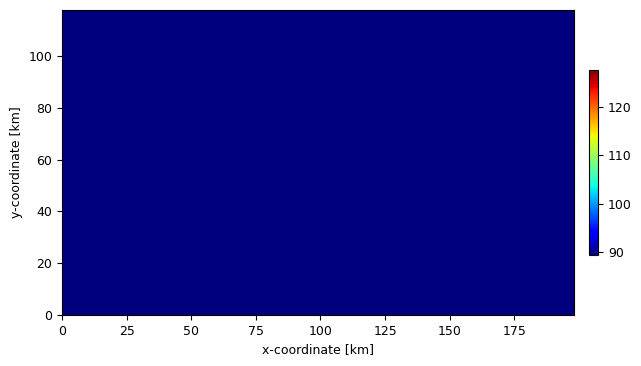

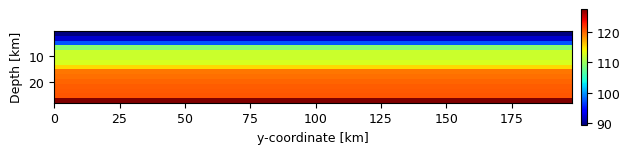

In [17]:
# Output folders 
output_folder_AWP="Example_1DVelocityModel_QpQs/outputData_QpQs/AWP_inputfiles/"
output_folder_Figures="Example_1DVelocityModel_QpQs/outputData_QpQs/Figures/"

# Remove existing output directories to prevent errors during execution.
# The binary file generation reads only the first modelcoords file it encounters.
if os.path.isdir(output_folder_AWP):
    print(f"Removing pre-existing output directory to avoid runtime conflicts:{output_folder_AWP}")
    shutil.rmtree(output_folder_AWP)
    
# Loading 1D velocity model
file_path = "Example_1DVelocityModel_QpQs/inputData/SoCal_1Dmodel_Anelastic.csv"
is_anelastic = True
model_data = VelocityModel_utils.parse_1d_model(file_path, is_anelastic=is_anelastic)

# Convert units of density from g/cm3 to kg/m3. 
model_data = VelocityModel_utils.convert_units(model_data,'km/s','g/cm3')

# Generate velocity model files for Southern California
model_lon=-119.38
model_lat=34.13
x_length=200    #km 
y_length=120    #km 
z_length=30     #km 
model_rot=-60   #deg
grid_spacing=2  #km 
Region= "SouthernCalifornia"

# Name of output files
domain_data = f'{int(x_length)}km_{int(y_length)}km_{int(z_length)}km_Spacing_{int(float(grid_spacing)*1000)}m'

# Generate velocity model coordinates file
VelocityModel_utils.create_model_coords_file(
    file_name=domain_data,
    site_name=Region,
    model_lon=model_lon,
    model_lat=model_lat,
    x_length=x_length,
    y_length=y_length,
    model_rot=model_rot,
    grid_spacing=grid_spacing,
    output_folder=output_folder_AWP)

# Generate model box
VelocityModel_utils.generate_modelbox_file(
    file_name=domain_data,
    site_name=Region,
    model_lon=model_lon,
    model_lat=model_lat,
    x_length=x_length,
    y_length=y_length,
    model_rot=model_rot,
    output_folder=output_folder_AWP)

# Generate gridout file
VelocityModel_utils.create_gridout_file(
    file_name=domain_data, 
    site_name=Region,
    x_length=x_length,
    y_length=y_length,
    z_length=z_length,
    grid_spacing=grid_spacing,
    output_folder=output_folder_AWP)

#  Plot domain on surface
VelocityModel_utils.plot_modelbox_with_folium(
    region=Region,
    model_lon=model_lon,
    model_lat=model_lat,
    x_length=x_length,
    y_length=y_length,
    model_rot=model_rot,
    output_folder=output_folder_Figures,
    display=False)

# Calculate the grid point in each direction based on the spacing
spacing = grid_spacing
X = np.arange(0, x_length, spacing, dtype=np.float32)
Y = np.arange(0, y_length, spacing, dtype=np.float32)
Z = np.arange(0, z_length, spacing, dtype=np.float32)

# Create the grid
Z_grid, Y_grid, X_grid = np.meshgrid(Z, Y, X, indexing='ij')

# Stack coordinates
coordinates = np.column_stack([X_grid.ravel(), Y_grid.ravel(), Z_grid.ravel()])
  
# Delete unneeded variables
del Z_grid, Y_grid, X_grid
VelocityModel_utils.force_gc()

# Print the result
print("Grid as column vector (X, Y, Z) with desired order:")
print("Coordinates:",coordinates)

# Delete unneeded variables
VelocityModel_utils.force_gc()

# Interpolate the 1D model
interpolated_values = VelocityModel_utils.interpolate_1d_model(model_data, coordinates, grid_spacing = spacing, method='linear', is_anelastic=is_anelastic)

# Generate dictionary with 
scatter_data = {
    'Depth': [coord[2] for coord in coordinates],  # Extracting Z (depth) coordinates
    'Vp': interpolated_values['vp'].tolist(),      # Vp values
    'Vs': interpolated_values['vs'].tolist(),      # Vs values
    'Rho':interpolated_values['rho'].tolist(),     # Rho values
    'Qp': interpolated_values['qp'].tolist(),
    'Qs': interpolated_values['qs'].tolist(),
}

# Assuming 'model_data' was parsed using parse_1d_model, plot the 1D model and interpolated values. 
VelocityModel_utils.plot_1d_model(output_folder_Figures, model_data, is_anelastic=is_anelastic, transition_type="linear",scatter_data=scatter_data,display=True)

# Create binary file 
VM_binFile=VelocityModel_utils.save_binary_model(region="SoCal_Anelastic", 
                  NX=len(X), NY=len(Y), NZ=len(Z), Dhkm=grid_spacing, 
                  z=coordinates[:, 2], Vp=interpolated_values['vp'], Vs=interpolated_values['vs'], Rho=interpolated_values['rho'], Qp=interpolated_values['qp'], Qs=interpolated_values['qs'], elastic=False,output_folder=output_folder_AWP)

# Plot XY surface 
VelocityModel_utils.plot_surface_XY(
    binary_file_path=VM_binFile,
    variable_name='Qp',
    index=0,
    num_x=len(X),
    num_y=len(Y),
    num_z=len(Z), 
    variable_names=['Vp', 'Vs', 'Rho','Qp','Qs'],
    output_folder=output_folder_Figures,
    x_coords = coordinates[:, 0],
    y_coords = coordinates[:, 1],
    z_coords = coordinates[:, 2])

# Plot XZ or YZ surface 
VelocityModel_utils.plot_surface_XZorYZ(
    binary_file_path=VM_binFile,
    variable_name='Qp',
    index=10, 
    num_x=len(X), 
    num_y=len(Y), 
    num_z=len(Z), 
    variable_names=['Vp', 'Vs', 'Rho','Qp','Qs'],
    plane_type='XZ',
    output_folder=output_folder_Figures,
    x_coords = coordinates[:, 0],
    y_coords = coordinates[:, 1],
    z_coords = coordinates[:, 2])